# RAG Evaluation Project: one problem, six failures, six evaluations
### Building a trustworthy AI assistant for an automobile service centre

**How this notebook works.** We take **one real industry problem** and try to solve it with AI. Each time our solution fails in a new way, we:

| Step | Question |
|---|---|
| 🔴 **Problem** | What went wrong? (shown with a real example) |
| 📏 **Evaluation** | Which metric *detects* this problem, and how bad is it? |
| 🛠️ **Fix** | What change to the RAG pipeline solves it? |
| ✅ **Re-evaluate** | Did the metric improve, without breaking anything else? |

By the end, you will see that **each type of evaluation exists to catch a specific type of failure**, and that RAG is built by measuring, not guessing.

| # | Failure | Evaluation that catches it | Fix |
|---|---|---|---|
| 1 | Chatbot invents answers (hallucination) | Key-fact accuracy, faithfulness | RAG over company documents |
| 2 | Right document, wrong piece of text | Evidence Hit@1 (context recall) | Better chunking |
| 3 | Answers from an outdated document | Stale-source rate | Metadata filtering |
| 4 | Confuses similar codes (P0A80 vs P0AA6) | Hit@1 and MRR per category | Hybrid search + re-ranking |
| 5 | Answers questions it should refuse | Negative-rejection rate | Relevance threshold |
| 6 | Answers can't be verified | Citation accuracy, LLM judge | Grounded answers with sources |

---
## 🚗 The business problem

**Volta Motors** (a fictional Indian EV maker) runs 40 authorised service centres. Every day, **service advisors** and **technicians** need answers to questions like:
- *"Car shows P0AA6. Can the customer drive it home?"*
- *"What is the deadline to submit this warranty claim?"*
- *"Is there a bulletin for this suspension rattle?"*

The answers are spread across warranty policies, technical service bulletins (TSBs), a diagnostic code guide, recall notices, labour-time guides and safety procedures. Bulletins get **revised**, policies get **replaced**, and codes look **almost identical**.

**What goes wrong today** *(scenario figures for this case study)*
- Finding an answer in the documents takes an advisor **about 10 minutes**
- Warranty claims get **rejected** because staff follow last year's policy
- A technician who follows an outdated bulletin does the **wrong repair**, and the car comes back
- On safety-critical codes, a wrong answer can put a customer or technician in **danger**

**The idea:** an AI assistant that answers these questions in seconds.

**Our success criteria (agreed with the service head before building anything)**

| Requirement | Metric | Target |
|---|---|---|
| Facts (numbers, part numbers, limits) must be right | Key-fact accuracy | ≥ 95% |
| The right piece of evidence must be found | Evidence Hit@1 | ≥ 95% |
| Never answer from an outdated document | Stale-source rate | 0% |
| Say "I don't know" when the documents don't cover it | Negative-rejection rate | 100% |
| Safety-critical questions | Key-fact accuracy on safety questions | 100% |
| Every answer shows its source | Citation accuracy | 100% |
| Fast enough to use at the service desk | Latency | < 2 seconds |

These targets become our **quality gates**. The assistant ships only when it passes all of them.

## ⚙️ Setup
Uncomment the install line on first run. Three small models download the first time (about 500 MB total).
If `ANTHROPIC_API_KEY` is set, the optional LLM cells use Claude; everything else runs without a key.

In [1]:
# !pip install -q sentence-transformers chromadb rank_bm25 langchain-text-splitters scikit-learn matplotlib pandas numpy anthropic

In [2]:
import os, re, time, json, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"; os.environ["TRANSFORMERS_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
BLUE, ORANGE, GREEN, RED, GREY, PURPLE = "#4C72B0", "#DD8452", "#55A868", "#C44E52", "#9aa5b1", "#8172B3"
HAS_LLM = bool(os.getenv("ANTHROPIC_API_KEY"))
pd.set_option("display.max_colwidth", 110)
print("LLM available:", HAS_LLM)

LLM available: False


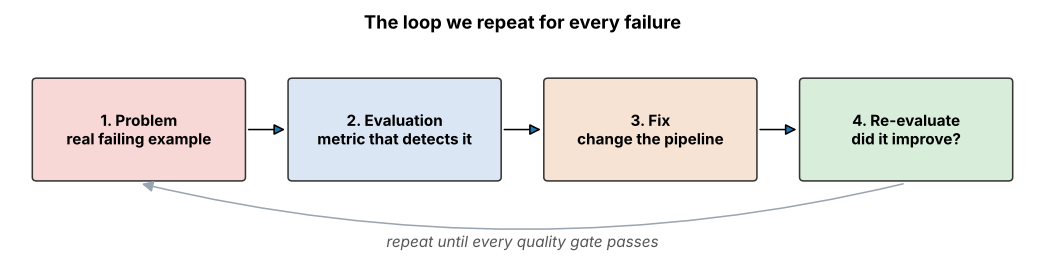

In [3]:
fig, ax = plt.subplots(figsize=(12, 2.6)); ax.set_xlim(0, 12); ax.set_ylim(-0.4, 2.6); ax.axis("off")
steps = [("1. Problem\nreal failing example", "#f8d7d7"), ("2. Evaluation\nmetric that detects it", "#dbe6f4"),
         ("3. Fix\nchange the pipeline", "#f6e3d3"), ("4. Re-evaluate\ndid it improve?", "#d8eedb")]
for i, (t, c) in enumerate(steps):
    ax.add_patch(FancyBboxPatch((0.3 + i * 3, 0.7), 2.4, 1.3, boxstyle="round,pad=0.05", fc=c, ec="#333"))
    ax.text(1.5 + i * 3, 1.35, t, ha="center", va="center", fontsize=10, fontweight="bold")
    if i < 3: ax.add_patch(FancyArrowPatch((2.75 + i * 3, 1.35), (3.25 + i * 3, 1.35), arrowstyle="-|>", mutation_scale=15))
ax.add_patch(FancyArrowPatch((10.5, 0.62), (1.5, 0.62), connectionstyle="arc3,rad=-0.12", arrowstyle="-|>", mutation_scale=15, color=GREY))
ax.text(6, -0.25, "repeat until every quality gate passes", ha="center", color="#555", style="italic")
ax.set_title("The loop we repeat for every failure", fontweight="bold"); plt.show()

---
## 📚 The data
### Service knowledge base
13 documents. Two are **outdated versions** that were never deleted from the shared drive, exactly like in real companies.

In [4]:
DOCUMENTS = [
  {"doc_id": "WAR-POL-2026", "type": "Warranty policy", "status": "current", "effective": "2026-01-01", "text": """
Volta Motors Warranty Policy 2026. Applies to all repair orders from 1 January 2026.

Rule 1. The vehicle warranty is 3 years or 100,000 km, whichever comes first. The high-voltage battery warranty is 8 years or 160,000 km and applies if capacity falls below 70%.

Rule 2. Warranty claims must be submitted within 30 days of the repair date, with the job card, photos of the failed part and the VDS diagnostic report attached.

Rule 3. A claim is rejected if non-genuine parts were fitted, or if a periodic service was skipped by more than 1,000 km.

Rule 4. Goodwill repairs outside warranty need written approval from the regional service manager before work starts.
"""},
  {"doc_id": "WAR-POL-2024", "type": "Warranty policy", "status": "superseded", "effective": "2024-01-01", "text": """
Volta Motors Warranty Policy 2024. Superseded on 1 January 2026.

Rule 2. Warranty claims must be submitted within 60 days of the repair date, with the job card attached.

Rule 3. A claim is rejected if non-genuine parts were fitted, or if a periodic service was skipped by more than 3,000 km.
"""},
  {"doc_id": "TSB-24-017-R1", "type": "Technical service bulletin", "status": "superseded", "effective": "2024-09-10", "text": """
TSB-24-017 Revision 1. Concern: rattling noise from the front suspension when driving over speed bumps on the Nexa EV.
Repair: tighten both front stabiliser link nuts to 65 Nm. Labour time 0.5 hours.
"""},
  {"doc_id": "TSB-24-017-R2", "type": "Technical service bulletin", "status": "current", "effective": "2026-02-01", "text": """
TSB-24-017 Revision 2 (supersedes Revision 1). Concern: rattling noise from the front suspension when driving over speed bumps on the Nexa EV.
Repair: replace both front stabiliser links with part VL-31400-B and torque the nuts to 80 Nm. Labour time 1.2 hours.
"""},
  {"doc_id": "TSB-25-004", "type": "Technical service bulletin", "status": "current", "effective": "2025-11-15", "text": """
TSB-25-004. Concern: the infotainment screen stays black after over-the-air software update 4.2.
Repair: hard reset by holding the volume knob for 15 seconds. If the screen stays black, reflash software 4.2.1 with the VDS tool. Labour time 0.3 hours.
"""},
  {"doc_id": "TSB-25-011", "type": "Technical service bulletin", "status": "current", "effective": "2025-08-20", "text": """
TSB-25-011. Concern: air conditioning not cooling on Nexa EVs built before June 2025.
Cause: faulty refrigerant pressure sensor. Repair: replace the sensor with part VL-80520-A. Labour time 0.8 hours.
"""},
  {"doc_id": "DTC-GUIDE", "type": "Diagnostic code guide", "status": "current", "effective": "2025-06-01", "text": """
DTC P0A80: one or more battery cells below voltage. Run the cell balance test with VDS. If any cell reads below 3.0 V, replace that battery module. Covered by battery warranty.

DTC P0A7F: battery pack deterioration, capacity below 70%. Run the capacity test and claim under the battery warranty if the car is within 8 years or 160,000 km.

DTC P0AA6: high-voltage isolation fault. SAFETY CRITICAL: the car must not be driven. Only HV-certified technicians may inspect it, wearing class 0 insulated gloves.

DTC U0100: lost communication with the motor control unit. Check CAN bus connector C12 for corrosion, then clean and re-seat it.

DTC B1342: airbag control module internal fault. Replace the airbag control unit, part VL-98820. Before any airbag work, disconnect the 12 V battery and wait 10 minutes.
"""},
  {"doc_id": "MAINT-SCHED", "type": "Maintenance schedule", "status": "current", "effective": "2025-01-01", "text": """
Periodic maintenance for the Nexa EV. The first free service is at 1,000 km or 1 month, then every 15,000 km or 12 months.

Brake fluid (DOT 4) is replaced every 2 years. The battery thermal-system coolant is replaced every 60,000 km or 4 years. The cabin air filter is replaced every 15,000 km.
"""},
  {"doc_id": "SPEC-SHEET", "type": "Technical specifications", "status": "current", "effective": "2025-01-01", "text": """
Nexa EV workshop specifications. Tyre pressure is 36 psi front and 34 psi rear, measured cold. Wheel nut torque is 120 Nm.

Fluids: the battery thermal system uses Volta G-48 coolant only; never mix it with other coolants. Brake fluid is DOT 4.
"""},
  {"doc_id": "LABOUR-GUIDE", "type": "Labour time guide", "status": "current", "effective": "2025-01-01", "text": """
Standard labour times for the Nexa EV, in hours: front brake pads 1.0; 12 V battery replacement 0.4; wheel alignment 0.8; cabin air filter 0.3; high-voltage battery module replacement 6.5.
"""},
  {"doc_id": "RECALL-RC-2026-03", "type": "Recall campaign", "status": "current", "effective": "2026-04-01", "text": """
Recall campaign RC-2026-03 covers Nexa EVs built from January to March 2026, VIN MA3NXE26A00001 to MA3NXE26A04500.
Replace the rear seat belt anchor bolt and torque it to 45 Nm. Labour time 0.6 hours, paid by Volta.
If an affected car is in the workshop for any reason, the recall must be completed before any other paid work.
"""},
  {"doc_id": "CUSTOMER-POLICY", "type": "Customer service policy", "status": "current", "effective": "2025-07-01", "text": """
A loaner car is offered when a warranty repair will take more than 24 hours. Pick-up and drop is free within 15 km of the service centre.

While a car is in the workshop, the service advisor must update the customer by SMS at least every 4 hours.
"""},
  {"doc_id": "HV-SAFETY-SOP", "type": "Safety procedure", "status": "current", "effective": "2025-03-01", "text": """
High-voltage safety procedure. Only HV-certified technicians may work on the orange high-voltage cables.
Before work: remove the service plug, wait 10 minutes, then confirm zero voltage with a CAT III meter.
"""},
]
docs_df = pd.DataFrame(DOCUMENTS)[["doc_id", "type", "status", "effective"]]
docs_df["characters"] = [len(d["text"]) for d in DOCUMENTS]
docs_df

,doc_id,type,status,effective,characters
0,WAR-POL-2026,Warranty policy,current,2026-01-01,670
1,WAR-POL-2024,Warranty policy,superseded,2024-01-01,295
2,TSB-24-017-R1,Technical service bulletin,superseded,2024-09-10,201
3,TSB-24-017-R2,Technical service bulletin,current,2026-02-01,262
4,TSB-25-004,Technical service bulletin,current,2025-11-15,252
5,TSB-25-011,Technical service bulletin,current,2025-08-20,202
6,DTC-GUIDE,Diagnostic code guide,current,2025-06-01,809
7,MAINT-SCHED,Maintenance schedule,current,2025-01-01,297
8,SPEC-SHEET,Technical specifications,current,2025-01-01,246
9,LABOUR-GUIDE,Labour time guide,current,2025-01-01,190


### The golden test set
22 real-style questions from advisors and technicians, each with a **reference answer**, the **document** that contains it and a short **evidence** phrase that marks the exact passage. Plus 4 questions the documents **cannot** answer.

Writing this set with the service team is the most valuable hour of the whole project: every metric below depends on it.

22 answerable questions, 4 out-of-scope questions


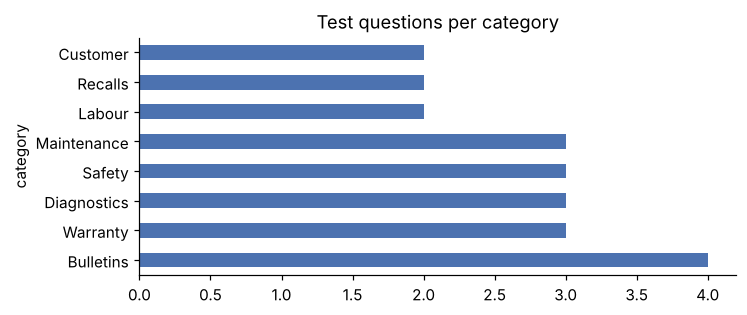

,question,reference,gold_doc,evidence,category
0,What is the deadline to submit a warranty claim?,"Within 30 days of the repair date, with job card, part photos and VDS report.",WAR-POL-2026,within 30 days,Warranty
1,When is a warranty claim rejected because of a skipped service?,"If a periodic service was skipped by more than 1,000 km.",WAR-POL-2026,"1,000 km",Warranty
2,Who must approve a goodwill repair?,"The regional service manager, in writing, before work starts.",WAR-POL-2026,Goodwill,Warranty
3,Customer reports front suspension rattle over speed bumps. What is the fix?,"Replace both front stabiliser links with part VL-31400-B and torque to 80 Nm (TSB-24-017 Rev 2), 1.2 hours.",TSB-24-017-R2,VL-31400-B,Bulletins
4,What labour time can we claim for TSB-24-017?,1.2 hours (Revision 2).,TSB-24-017-R2,1.2 hours,Bulletins
5,Infotainment screen is black after the OTA update. What should the technician do?,"Hold the volume knob for 15 seconds; if still black, reflash software 4.2.1 with VDS.",TSB-25-004,volume knob,Bulletins


In [5]:
# (question asked by a service advisor or technician, reference answer, gold document, evidence text that marks the right chunk, category)
GOLDEN = [
    ("What is the deadline to submit a warranty claim?", "Within 30 days of the repair date, with job card, part photos and VDS report.", "WAR-POL-2026", "within 30 days", "Warranty"),
    ("When is a warranty claim rejected because of a skipped service?", "If a periodic service was skipped by more than 1,000 km.", "WAR-POL-2026", "1,000 km", "Warranty"),
    ("Who must approve a goodwill repair?", "The regional service manager, in writing, before work starts.", "WAR-POL-2026", "Goodwill", "Warranty"),
    ("Customer reports front suspension rattle over speed bumps. What is the fix?", "Replace both front stabiliser links with part VL-31400-B and torque to 80 Nm (TSB-24-017 Rev 2), 1.2 hours.", "TSB-24-017-R2", "VL-31400-B", "Bulletins"),
    ("What labour time can we claim for TSB-24-017?", "1.2 hours (Revision 2).", "TSB-24-017-R2", "1.2 hours", "Bulletins"),
    ("Infotainment screen is black after the OTA update. What should the technician do?", "Hold the volume knob for 15 seconds; if still black, reflash software 4.2.1 with VDS.", "TSB-25-004", "volume knob", "Bulletins"),
    ("AC is not cooling on a Nexa built in 2025. Any bulletin?", "TSB-25-011: replace the refrigerant pressure sensor VL-80520-A, 0.8 hours.", "TSB-25-011", "VL-80520-A", "Bulletins"),
    ("What does DTC P0A80 mean and what is the repair?", "Battery cells below voltage; run the cell balance test and replace any module with a cell below 3.0 V.", "DTC-GUIDE", "P0A80", "Diagnostics"),
    ("Scan tool shows P0A7F. What next?", "Capacity below 70%; run the capacity test and claim under battery warranty within 8 years or 160,000 km.", "DTC-GUIDE", "P0A7F", "Diagnostics"),
    ("Car shows P0AA6. Can the customer drive it home?", "No. High-voltage isolation fault: the car must not be driven; only HV-certified technicians with class 0 gloves may inspect it.", "DTC-GUIDE", "P0AA6", "Safety"),
    ("How do I fix U0100?", "Check CAN bus connector C12 for corrosion, then clean and re-seat it.", "DTC-GUIDE", "U0100", "Diagnostics"),
    ("B1342 airbag fault: what precautions before the repair?", "Disconnect the 12 V battery and wait 10 minutes; replace airbag control unit VL-98820.", "DTC-GUIDE", "B1342", "Safety"),
    ("When should the battery coolant be replaced?", "Every 60,000 km or 4 years.", "MAINT-SCHED", "60,000 km", "Maintenance"),
    ("Which coolant goes in the battery thermal system?", "Volta G-48 coolant only.", "SPEC-SHEET", "G-48", "Maintenance"),
    ("What is the wheel nut torque?", "120 Nm.", "SPEC-SHEET", "120 Nm", "Maintenance"),
    ("How long should a front brake pad job take?", "1.0 hour.", "LABOUR-GUIDE", "front brake pads", "Labour"),
    ("Standard labour time for replacing an HV battery module?", "6.5 hours.", "LABOUR-GUIDE", "6.5", "Labour"),
    ("Which VINs are covered by recall RC-2026-03?", "Cars built January to March 2026, VIN MA3NXE26A00001 to MA3NXE26A04500.", "RECALL-RC-2026-03", "MA3NXE26A00001", "Recalls"),
    ("A car in the RC-2026-03 range came in for a paid service. What do we do first?", "Complete the recall (seat belt anchor bolt, 45 Nm) before any other paid work.", "RECALL-RC-2026-03", "before any other paid work", "Recalls"),
    ("When do we give the customer a loaner car?", "When a warranty repair will take more than 24 hours.", "CUSTOMER-POLICY", "24 hours", "Customer"),
    ("How often must the advisor update the customer while the car is in the workshop?", "By SMS at least every 4 hours.", "CUSTOMER-POLICY", "every 4 hours", "Customer"),
    ("What must a technician do before working on the orange HV cables?", "Remove the service plug, wait 10 minutes and confirm zero voltage with a CAT III meter.", "HV-SAFETY-SOP", "service plug", "Safety"),
]

# Questions the knowledge base cannot answer: the assistant must say so instead of guessing
OUT_OF_SCOPE = [
    "What is the ex-showroom price of the Nexa Max?",
    "What is this quarter's incentive for service advisors?",
    "How do I replace a diesel fuel injector?",
    "What is the dealer margin on accessories?",
]
gold_df = pd.DataFrame(GOLDEN, columns=["question", "reference", "gold_doc", "evidence", "category"])
print(len(GOLDEN), "answerable questions,", len(OUT_OF_SCOPE), "out-of-scope questions")
gold_df.category.value_counts().plot.barh(color=BLUE, figsize=(7, 2.8), title="Test questions per category"); plt.show()
gold_df.head(6)

### The evaluation toolkit
We define every metric once and reuse it at every step.

| Metric | What it checks | Needs |
|---|---|---|
| **Key-fact accuracy** | Are all numbers in the reference (days, km, Nm, hours, part numbers) in the answer? | reference answer |
| **Faithfulness** | Is every claim in the answer supported by the source document? (NLI model) | source text |
| **Evidence Hit@1** | Is the top retrieved chunk the one that holds the evidence? | gold doc + evidence |
| **MRR** | How high is the right chunk ranked? (1 = first, 0.5 = second …) | gold doc + evidence |
| **Stale-source rate** | Share of answers taken from an outdated document | document status |
| **Negative-rejection rate** | Share of out-of-scope questions the bot refuses | out-of-scope set |
| **Citation accuracy** | Does the answer cite the correct document? | gold doc |

In [6]:
from sentence_transformers import SentenceTransformer, CrossEncoder
embedder = SentenceTransformer("all-MiniLM-L6-v2")                     # embeddings for search
reranker = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2")       # relevance scoring (problem 4-5)
nli = CrossEncoder("cross-encoder/nli-MiniLM2-L6-H768")               # fact checking (faithfulness)
REFUSAL = "I couldn't find this in the Volta service documents. Please check with the service manager."

def numbers(text):
    t = text.replace(",", "")
    # codes like P0AA6, VL-31400-B, MA3NXE26A00001 count as one token; plain numbers like 30, 1.2, 160000 as another
    return set(re.findall(r"\b[A-Z]{1,3}-?\d[0-9A-Z-]*\b|\b\d+(?:\.\d+)?\b", t))

def key_fact_accuracy(answer, reference):
    need = numbers(reference)
    return len(need & numbers(answer)) / len(need) if need else np.nan

def faithfulness(answer, source):
    """Share of answer sentences that the NLI model says are ENTAILED by some sentence of the source."""
    claims = [c for c in re.split(r"(?<=[.!?])\s+", answer) if len(c.split()) >= 3]
    premises = [p for p in re.split(r"(?<=[.!?])\s+", source) if p] + [source]
    ok = 0
    for c in claims:
        probs = nli.predict([(p, c) for p in premises], apply_softmax=True)   # columns: contradiction, entailment, neutral
        best = probs[np.argmax(probs[:, 1])]
        ok += int(np.argmax(best) == 1)
    return ok / len(claims) if claims else 1.0

def is_refusal(answer): return answer.startswith("I couldn't find")
print("toolkit ready ·", numbers("Torque to 80 Nm, part VL-31400-B, 1.2 hours"))

toolkit ready · {'1.2', 'VL-31400-B', '80'}


---
## 🔴 Problem 1: "Just ask ChatGPT" gives confident, wrong answers
A new advisor tries a general chatbot first. It has never seen Volta's documents, so it answers from general car knowledge.

*Try it yourself in class: ask any public chatbot a few of the golden questions and compare with the reference answers.*

In [7]:
# What a general chatbot (no access to Volta's documents) typically answers.
# SIMULATED: written by hand to show common failure patterns. With an API key you can generate real ones below.
CLOSED_BOOK = {
    "What is the deadline to submit a warranty claim?": "Warranty claims usually need to be submitted within 90 days of the repair.",
    "When is a warranty claim rejected because of a skipped service?": "A claim can be rejected if a service is delayed by more than 5,000 km or 6 months.",
    "Who must approve a goodwill repair?": "Goodwill repairs are normally approved by the dealership's own service manager.",
    "Customer reports front suspension rattle over speed bumps. What is the fix?": "Tighten the front stabiliser link nuts to 65 Nm; loose links are the usual cause of this rattle.",
    "What labour time can we claim for TSB-24-017?": "TSB-24-017 allows 0.5 hours of labour.",
    "Infotainment screen is black after the OTA update. What should the technician do?": "Restart the car and wait 5 minutes. If the screen is still black, do a factory reset from the settings menu.",
    "AC is not cooling on a Nexa built in 2025. Any bulletin?": "Check the refrigerant level and recharge the AC gas; low refrigerant is the most common cause.",
    "What does DTC P0A80 mean and what is the repair?": "P0A80 means Replace Hybrid Battery Pack. The complete battery pack should be replaced.",
    "Scan tool shows P0A7F. What next?": "P0A7F indicates hybrid battery deterioration. Replace the battery pack.",
    "Car shows P0AA6. Can the customer drive it home?": "P0AA6 is an isolation fault in the hybrid system. The car can usually be driven carefully to the workshop.",
    "How do I fix U0100?": "U0100 means lost communication with the ECM. Check the ECM fuses and wiring harness.",
    "B1342 airbag fault: what precautions before the repair?": "B1342 indicates an internal ECU failure. Replace the airbag module and clear the codes.",
    "When should the battery coolant be replaced?": "Battery coolant is usually replaced every 100,000 km or 5 years.",
    "Which coolant goes in the battery thermal system?": "Any OAT-based long-life coolant can be used.",
    "What is the wheel nut torque?": "Wheel nut torque for passenger cars is typically 100 to 110 Nm.",
    "How long should a front brake pad job take?": "A front brake pad replacement takes about 1.5 hours.",
    "Standard labour time for replacing an HV battery module?": "Replacing an HV battery module takes around 4 hours.",
    "Which VINs are covered by recall RC-2026-03?": "Recall RC-2026-03 covers Nexa EVs built in 2025.",
    "A car in the RC-2026-03 range came in for a paid service. What do we do first?": "Do the paid service, inform the customer about the recall and book it for a later visit.",
    "When do we give the customer a loaner car?": "A loaner car is offered when the repair takes more than 48 hours.",
    "How often must the advisor update the customer while the car is in the workshop?": "Update the customer once a day.",
    "What must a technician do before working on the orange HV cables?": "Switch off the ignition and wear insulated gloves.",
    "What is the ex-showroom price of the Nexa Max?": "The Nexa Max is priced at about Rs 17.5 lakh ex-showroom.",
    "What is this quarter's incentive for service advisors?": "Service advisors get Rs 500 per paid service this quarter.",
    "How do I replace a diesel fuel injector?": "Remove the injector clamp bolt, disconnect the fuel line, pull out the injector and fit it with a new copper washer.",
    "What is the dealer margin on accessories?": "Dealer margin on accessories is usually around 25%.",
}

In [8]:
# Optional: generate REAL closed-book answers with an LLM (no documents given) instead of the simulated ones
def ask_llm(prompt, max_tokens=250):
    import anthropic
    msg = anthropic.Anthropic().messages.create(model="claude-sonnet-5-5", max_tokens=max_tokens,
                                                messages=[{"role": "user", "content": prompt}])
    return msg.content[0].text

if HAS_LLM and False:      # change False to True to replace the simulated answers
    for q in CLOSED_BOOK:
        CLOSED_BOOK[q] = ask_llm(f"You are a service advisor at a Volta Motors EV dealership. Answer briefly: {q}")

for q in ["Car shows P0AA6. Can the customer drive it home?", "What is the deadline to submit a warranty claim?"]:
    ref = gold_df.set_index("question").loc[q, "reference"]
    print(f"Q: {q}\n   Chatbot : {CLOSED_BOOK[q]}\n   Correct : {ref}\n")

Q: Car shows P0AA6. Can the customer drive it home?
   Chatbot : P0AA6 is an isolation fault in the hybrid system. The car can usually be driven carefully to the workshop.
   Correct : No. High-voltage isolation fault: the car must not be driven; only HV-certified technicians with class 0 gloves may inspect it.

Q: What is the deadline to submit a warranty claim?
   Chatbot : Warranty claims usually need to be submitted within 90 days of the repair.
   Correct : Within 30 days of the repair date, with job card, part photos and VDS report.



### 📏 Evaluation: key-fact accuracy + faithfulness
The answers *sound* fine, so reading a few of them is not enough. We measure:
- **Key-fact accuracy** against the reference answers
- **Faithfulness** against the official document: is each claim actually supported by Volta's documentation?
- **Negative rejection** on the 4 questions no document can answer

In [9]:
DOC_TEXT = {d["doc_id"]: re.sub(r"\s+", " ", d["text"]).strip() for d in DOCUMENTS}

def evidence_passage(doc_id, evidence):
    """The paragraph of the gold document that contains the evidence phrase."""
    paras = [re.sub(r"\s+", " ", p).strip() for d in DOCUMENTS if d["doc_id"] == doc_id for p in d["text"].split("\n\n")]
    return next((p for p in paras if evidence in p), DOC_TEXT[doc_id])

rows = []
for q, ref, doc, ev, cat in GOLDEN:
    a = CLOSED_BOOK[q]
    rows.append({"question": q, "category": cat, "answer": a, "key_fact": key_fact_accuracy(a, ref),
                 "faithful": faithfulness(a, evidence_passage(doc, ev))})
s0 = pd.DataFrame(rows)
s0_refusal = np.mean([is_refusal(CLOSED_BOOK[q]) for q in OUT_OF_SCOPE])
print(f"Key-fact accuracy : {s0.key_fact.mean():.0%}")
print(f"Faithfulness      : {s0.faithful.mean():.0%}")
print(f"Negative rejection: {s0_refusal:.0%}  (it answered all {len(OUT_OF_SCOPE)} out-of-scope questions)")
s0[["question", "answer", "key_fact", "faithful"]].head(8)

Key-fact accuracy : 0%
Faithfulness      : 16%
Negative rejection: 0%  (it answered all 4 out-of-scope questions)


,question,answer,key_fact,faithful
0,What is the deadline to submit a warranty claim?,Warranty claims usually need to be submitted within 90 days of the repair.,0.0,0.0
1,When is a warranty claim rejected because of a skipped service?,"A claim can be rejected if a service is delayed by more than 5,000 km or 6 months.",0.0,0.0
2,Who must approve a goodwill repair?,Goodwill repairs are normally approved by the dealership's own service manager.,NaN,0.0
3,Customer reports front suspension rattle over speed bumps. What is the fix?,Tighten the front stabiliser link nuts to 65 Nm; loose links are the usual cause of this rattle.,0.0,0.0
4,What labour time can we claim for TSB-24-017?,TSB-24-017 allows 0.5 hours of labour.,0.0,0.0
5,Infotainment screen is black after the OTA update. What should the technician do?,"Restart the car and wait 5 minutes. If the screen is still black, do a factory reset from the settings menu.",0.0,0.0
6,AC is not cooling on a Nexa built in 2025. Any bulletin?,Check the refrigerant level and recharge the AC gas; low refrigerant is the most common cause.,0.0,0.0
7,What does DTC P0A80 mean and what is the repair?,P0A80 means Replace Hybrid Battery Pack. The complete battery pack should be replaced.,0.0,0.0


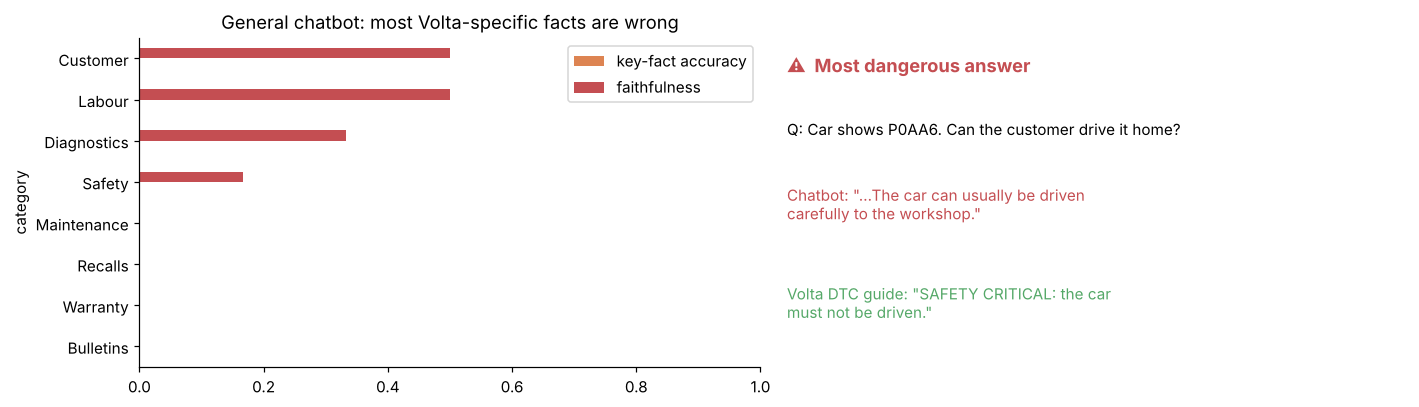

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
by_cat = s0.groupby("category")[["key_fact", "faithful"]].mean().sort_values("faithful")
by_cat.plot.barh(ax=axes[0], color=[ORANGE, RED]); axes[0].set_xlim(0, 1)
axes[0].set_title("General chatbot: most Volta-specific facts are wrong"); axes[0].legend(["key-fact accuracy", "faithfulness"])
axes[1].axis("off")
axes[1].text(0, 0.95, "⚠️  Most dangerous answer", fontsize=12, fontweight="bold", color=RED, va="top")
axes[1].text(0, 0.75, "Q: Car shows P0AA6. Can the customer drive it home?", fontsize=10, va="top")
axes[1].text(0, 0.55, "Chatbot: \"...The car can usually be driven\ncarefully to the workshop.\"", fontsize=10, va="top", color=RED)
axes[1].text(0, 0.25, "Volta DTC guide: \"SAFETY CRITICAL: the car\nmust not be driven.\"", fontsize=10, va="top", color=GREEN)
plt.tight_layout(); plt.show()

**Diagnosis.** The chatbot's language is fluent; its *facts* are not Volta's. It invents deadlines (90 days instead of 30), follows the old bulletin, and gives an unsafe answer on a high-voltage fault. It also answers every out-of-scope question with made-up numbers.

### 🛠️ Fix: Retrieval-Augmented Generation (RAG)
Give the model Volta's own documents at question time. Our first, simplest version:
**load → clean → chunk (fixed 120 characters) → embed → vector DB → retrieve top-1 → answer from it.**

In [11]:
import chromadb
from langchain_text_splitters import RecursiveCharacterTextSplitter

def clean(text):
    return re.sub(r"[ \t]+", " ", text).strip()

def fixed_size_chunks(size=120):
    """Naive chunking: cut every `size` characters, no matter where words or sentences end."""
    out = []
    for d in DOCUMENTS:
        t = re.sub(r"\s+", " ", clean(d["text"]))
        for i in range(0, len(t), size):
            out.append({"doc_id": d["doc_id"], "status": d["status"], "effective": d["effective"], "text": t[i:i + size]})
    return out

client = chromadb.Client()
class Store:
    """Chunks + Chroma vector index + helpers, so each pipeline version can use its own chunks."""
    def __init__(self, name, chunks):
        self.chunks = chunks
        try: client.delete_collection(name)
        except Exception: pass
        self.col = client.create_collection(name, metadata={"hnsw:space": "cosine"})
        self.col.add(ids=[str(i) for i in range(len(chunks))], documents=[c["text"] for c in chunks],
                     embeddings=embedder.encode([c["text"] for c in chunks], normalize_embeddings=True).tolist(),
                     metadatas=[{"doc_id": c["doc_id"], "status": c["status"]} for c in chunks])
    def dense(self, q, k=10, where=None):
        r = self.col.query(query_embeddings=embedder.encode([q], normalize_embeddings=True).tolist(),
                           n_results=k, where=where)
        return [int(i) for i in r["ids"][0]], [1 - d for d in r["distances"][0]]

store_fixed = Store("fixed_chunks", fixed_size_chunks())
print("Fixed-size chunks:", len(store_fixed.chunks))

Fixed-size chunks: 42


In [12]:
def evaluate(store, retrieve, answer_fn=None, name=""):
    """Run the golden set + out-of-scope set through one pipeline and compute every metric."""
    rows = []
    for q, ref, doc, ev, cat in GOLDEN:
        t0 = time.perf_counter()
        ids, scores = retrieve(store, q)
        refused = answer_fn is not None and answer_fn(store, q, ids, scores) == REFUSAL
        top = store.chunks[ids[0]]
        answer = REFUSAL if refused else top["text"]
        hit = (not refused) and top["doc_id"] == doc and ev in top["text"]
        rank = next((r for r, i in enumerate(ids, 1) if store.chunks[i]["doc_id"] == doc and ev in store.chunks[i]["text"]), None)
        rows.append({"question": q, "category": cat, "answer": answer, "top_doc": top["doc_id"],
                     "evidence_hit@1": float(hit), "rr": 1 / rank if rank else 0.0,
                     "stale": float(top["status"] == "superseded" and not refused),
                     "key_fact": 0.0 if refused else key_fact_accuracy(answer, ref),
                     "refused": float(refused), "latency_ms": (time.perf_counter() - t0) * 1000})
    oos = []
    for q in OUT_OF_SCOPE:
        ids, scores = retrieve(store, q)
        oos.append(answer_fn is not None and answer_fn(store, q, ids, scores) == REFUSAL)
    df = pd.DataFrame(rows)
    summary = {"Key-fact accuracy": df.key_fact.mean(), "Evidence Hit@1": df["evidence_hit@1"].mean(),
               "MRR": df.rr.mean(), "Stale-source rate": df.stale.mean(),
               "Negative rejection": float(np.mean(oos)), "Safety key-facts": df[df.category == "Safety"].key_fact.mean(),
               "Wrongly refused": df.refused.mean(), "Latency p95 (ms)": df.latency_ms.quantile(0.95)}
    return df, pd.Series(summary, name=name)

dense_top = lambda store, q: store.dense(q, 10)
s1_df, s1 = evaluate(store_fixed, dense_top, name="S1 Naive RAG")
S0 = pd.Series({"Key-fact accuracy": s0.key_fact.mean(), "Negative rejection": s0_refusal,
                "Safety key-facts": s0[s0.category == "Safety"].key_fact.mean()}, name="S0 Chatbot (no RAG)")
HISTORY = [S0, s1]
pd.concat(HISTORY, axis=1).T.round(2)

,Key-fact accuracy,Negative rejection,Safety key-facts,Evidence Hit@1,MRR,Stale-source rate,Wrongly refused,Latency p95 (ms)
S0 Chatbot (no RAG),0.00,0.0,0.0,NaN,NaN,NaN,NaN,NaN
S1 Naive RAG,0.44,0.0,0.0,0.45,0.57,0.09,0.0,19.96


### ✅ Re-evaluate
Key-fact accuracy jumps because answers now come from Volta's documents, not the model's imagination. Problem 1 is solved... but the other metrics show **new** problems. Let's look at them one by one.

---
## 🔴 Problem 2: right document, wrong piece of text (bad chunking)
Look at what the naive RAG returns for a diagnostic question:

In [13]:
q = "What does DTC P0A80 mean and what is the repair?"
row = s1_df.set_index("question").loc[q]
print("Q:", q); print("Retrieved chunk:", repr(row.answer)); print("Evidence found in top chunk?", bool(row["evidence_hit@1"]))

Q: What does DTC P0A80 mean and what is the repair?
Retrieved chunk: 'eplace that battery module. Covered by battery warranty. DTC P0A7F: battery pack deterioration, capacity below 70%. Run '
Evidence found in top chunk? False


The chunk starts in the **middle of a sentence** and mixes the end of one code with the start of the next. Fixed-size chunking cut the documents at every 120th character, regardless of meaning.

### 📏 Evaluation: Evidence Hit@1 (context recall)
Does the top chunk contain the evidence that answers the question? This is a **retrieval** metric: it tells us the answer failed *before* the LLM even saw the text.

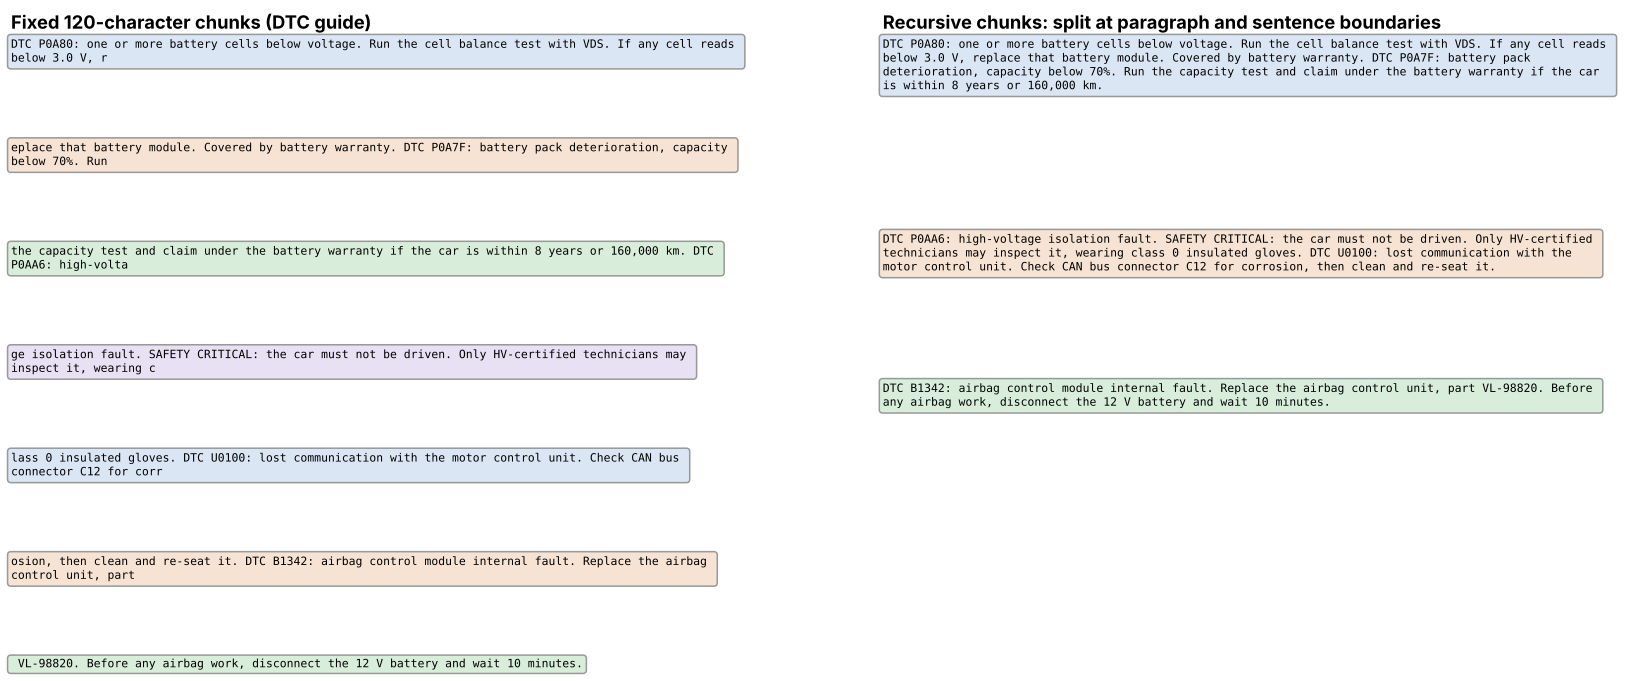

In [14]:
def show_chunks(chunks, doc_id, title, ax):
    """Draw how one document is split into chunks: each colour is one chunk."""
    parts = [c["text"] for c in chunks if c["doc_id"] == doc_id]
    ax.axis("off"); ax.set_title(title, fontweight="bold", loc="left")
    y = 1.0
    for i, p in enumerate(parts):
        wrapped = "\n".join(re.findall(r".{1,105}(?:\s|$)", p))
        ax.text(0, y, wrapped, fontsize=7.5, va="top", family="monospace",
                bbox=dict(boxstyle="round", fc=["#dbe6f4", "#f6e3d3", "#d8eedb", "#e8e0f3"][i % 4], ec="#999"))
        y -= 0.115 * (wrapped.count("\n") + 1) + 0.03

def recursive_chunks(size=350, overlap=30):
    """Split on paragraphs first, then lines, then sentences: chunks follow the document's structure."""
    splitter = RecursiveCharacterTextSplitter(chunk_size=size, chunk_overlap=overlap, separators=["\n\n", "\n", ". ", " "])
    out = []
    for d in DOCUMENTS:
        for piece in splitter.split_text(clean(d["text"])):
            out.append({"doc_id": d["doc_id"], "status": d["status"], "effective": d["effective"],
                        "text": re.sub(r"\s+", " ", piece)})
    return out

fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
show_chunks(fixed_size_chunks(), "DTC-GUIDE", "Fixed 120-character chunks (DTC guide)", axes[0])
show_chunks(recursive_chunks(), "DTC-GUIDE", "Recursive chunks: split at paragraph and sentence boundaries", axes[1])
plt.tight_layout(); plt.show()

### 🛠️ Fix: structure-aware (recursive) chunking
`RecursiveCharacterTextSplitter` (from 3.1) splits on paragraph breaks first, then lines, then sentences, so a rule, bulletin or diagnostic code is never cut in the middle. A 30-character overlap protects facts that sit on a boundary.

**But which chunk size?** Don't guess: let the evaluation choose. Too small splits a bulletin's *concern* from its *repair*; too large mixes several codes into one chunk.

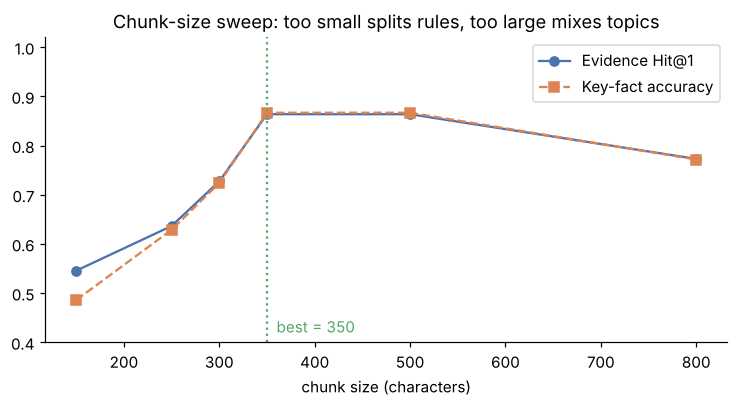

,chunks,Evidence Hit@1,Key-fact accuracy
chunk size,,,
150,43,0.55,0.49
250,24,0.64,0.63
300,19,0.73,0.72
350,17,0.86,0.87
500,15,0.86,0.87
800,14,0.77,0.77


In [15]:
sweep = []
for size in [150, 250, 300, 350, 500, 800]:
    st = Store(f"sweep_{size}", recursive_chunks(size=size))
    df, summ = evaluate(st, dense_top)
    sweep.append({"chunk size": size, "chunks": len(st.chunks), "Evidence Hit@1": summ["Evidence Hit@1"],
                  "Key-fact accuracy": summ["Key-fact accuracy"]})
sweep = pd.DataFrame(sweep).set_index("chunk size")
BEST_SIZE = int(sweep["Evidence Hit@1"].idxmax())

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(sweep.index, sweep["Evidence Hit@1"], "o-", color=BLUE, label="Evidence Hit@1")
ax.plot(sweep.index, sweep["Key-fact accuracy"], "s--", color=ORANGE, label="Key-fact accuracy")
ax.axvline(BEST_SIZE, color=GREEN, ls=":"); ax.text(BEST_SIZE + 10, 0.42, f"best = {BEST_SIZE}", color=GREEN)
ax.set_xlabel("chunk size (characters)"); ax.set_ylim(0.4, 1.02); ax.legend()
ax.set_title("Chunk-size sweep: too small splits rules, too large mixes topics"); plt.show()
sweep.round(2)

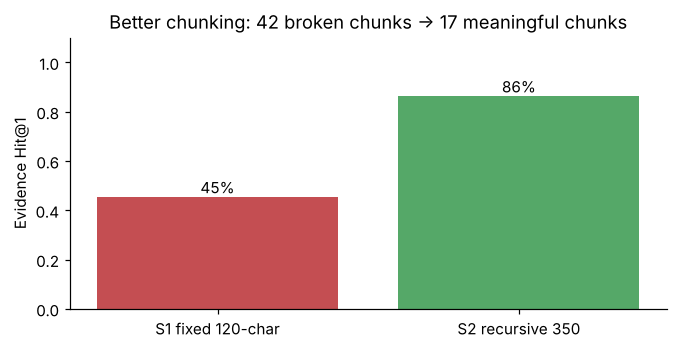

,Key-fact accuracy,Negative rejection,Safety key-facts,Evidence Hit@1,MRR,Stale-source rate,Wrongly refused,Latency p95 (ms)
S0 Chatbot (no RAG),0.00,0.0,0.0,NaN,NaN,NaN,NaN,NaN
S1 Naive RAG,0.44,0.0,0.0,0.45,0.57,0.09,0.0,19.96
S2 + recursive chunking,0.87,0.0,1.0,0.86,0.92,0.05,0.0,20.41


In [16]:
store_rec = Store("recursive_chunks", recursive_chunks(size=BEST_SIZE))
s2_df, s2 = evaluate(store_rec, dense_top, name="S2 + recursive chunking")
HISTORY.append(s2)

fig, ax = plt.subplots(figsize=(7, 3.2))
vals = [s1["Evidence Hit@1"], s2["Evidence Hit@1"]]
bars = ax.bar(["S1 fixed 120-char", f"S2 recursive {BEST_SIZE}"], vals, color=[RED, GREEN]); ax.bar_label(bars, labels=[f"{v:.0%}" for v in vals])
ax.set_ylim(0, 1.1); ax.set_ylabel("Evidence Hit@1")
ax.set_title(f"Better chunking: {len(store_fixed.chunks)} broken chunks → {len(store_rec.chunks)} meaningful chunks")
plt.show()
pd.concat(HISTORY, axis=1).T.round(2)

---
## 🔴 Problem 3: answers from an outdated document

In [17]:
q = "Customer reports front suspension rattle over speed bumps. What is the fix?"
row = s2_df.set_index("question").loc[q]
print("Q:", q); print("Answer from:", row.top_doc); print(" ", row.answer)
print("\nBut the current bulletin says:\n ", DOC_TEXT["TSB-24-017-R2"][:230])

Q: Customer reports front suspension rattle over speed bumps. What is the fix?
Answer from: TSB-24-017-R1
  TSB-24-017 Revision 1. Concern: rattling noise from the front suspension when driving over speed bumps on the Nexa EV. Repair: tighten both front stabiliser link nuts to 65 Nm. Labour time 0.5 hours.

But the current bulletin says:
  TSB-24-017 Revision 2 (supersedes Revision 1). Concern: rattling noise from the front suspension when driving over speed bumps on the Nexa EV. Repair: replace both front stabiliser links with part VL-31400-B and torque the nuts to


Revision 1 and Revision 2 of the bulletin are almost identical in wording, so their embeddings are almost identical too. Semantic search **cannot know which one is current**. The technician would tighten the nuts to 65 Nm instead of replacing the links, and the car comes back.

### 📏 Evaluation: stale-source rate
Share of answers whose top chunk comes from a superseded document. Our gate is **0%**.

In [18]:
stale = s2_df[s2_df.stale == 1][["question", "top_doc"]]
print(f"Stale-source rate in S2: {s2['Stale-source rate']:.0%}"); stale

Stale-source rate in S2: 5%


,question,top_doc
3,Customer reports front suspension rattle over speed bumps. What is the fix?,TSB-24-017-R1


### 🛠️ Fix: metadata filtering
Every chunk carries metadata from ingestion (`status`, `effective` date). We filter **before** ranking so outdated chunks can never be retrieved. (Real systems also archive superseded documents, but a filter protects you when someone forgets.)

In [19]:
dense_current = lambda store, q: store.dense(q, 10, where={"status": "current"})
s3_df, s3 = evaluate(store_rec, dense_current, name="S3 + metadata filter")
HISTORY.append(s3)
row = s3_df.set_index("question").loc[q]
print("Now answered from:", row.top_doc, "→", row.answer[:120], "...\n")
pd.concat(HISTORY, axis=1).T.round(2)

Now answered from: TSB-24-017-R2 → TSB-24-017 Revision 2 (supersedes Revision 1). Concern: rattling noise from the front suspension when driving over speed ...



,Key-fact accuracy,Negative rejection,Safety key-facts,Evidence Hit@1,MRR,Stale-source rate,Wrongly refused,Latency p95 (ms)
S0 Chatbot (no RAG),0.00,0.0,0.0,NaN,NaN,NaN,NaN,NaN
S1 Naive RAG,0.44,0.0,0.0,0.45,0.57,0.09,0.0,19.96
S2 + recursive chunking,0.87,0.0,1.0,0.86,0.92,0.05,0.0,20.41
S3 + metadata filter,0.90,0.0,1.0,0.91,0.94,0.00,0.0,18.65


---
## 🔴 Problem 4: confusing similar codes and IDs
Service work is full of codes that look alike: `P0A80`, `P0A7F`, `P0AA6`, `TSB-24-017`, `VL-31400-B`. Which questions still fail?

In [20]:
misses = s3_df[s3_df["evidence_hit@1"] == 0][["question", "category", "top_doc", "answer"]]
misses

,question,category,top_doc,answer
4,What labour time can we claim for TSB-24-017?,Bulletins,LABOUR-GUIDE,"Standard labour times for the Nexa EV, in hours: front brake pads 1.0; 12 V battery replacement 0.4; wheel..."
7,What does DTC P0A80 mean and what is the repair?,Diagnostics,DTC-GUIDE,DTC P0AA6: high-voltage isolation fault. SAFETY CRITICAL: the car must not be driven. Only HV-certified te...


The P0A80 question gets the **P0AA6** chunk (a different fault, with different actions), and the TSB-24-017 labour question gets the general labour guide. To an embedding model these strings look nearly the same; the exact code is what matters.

### 📏 Evaluation: Hit@1 and MRR per category
Averages hide where the problem is, so we break the retrieval metric down **by category**.

In [21]:
def per_category(df): return df.groupby("category")["evidence_hit@1"].mean()
cat_table = pd.DataFrame({"S3 dense + filter": per_category(s3_df)})
cat_table.style.format("{:.0%}").background_gradient(cmap="RdYlGn", vmin=0, vmax=1)

,S3 dense + filter
category,
Bulletins,75%
Customer,100%
Diagnostics,67%
Labour,100%
Maintenance,100%
Recalls,100%
Safety,100%
Warranty,100%


### 🛠️ Fix: hybrid search + re-ranking (from 3.3)
1. **BM25 keyword search** matches exact codes like `P0A80` and `TSB-24-017`
2. **Reciprocal Rank Fusion** merges keyword and dense results
3. A **cross-encoder re-ranker** reads question + chunk together and orders the final candidates

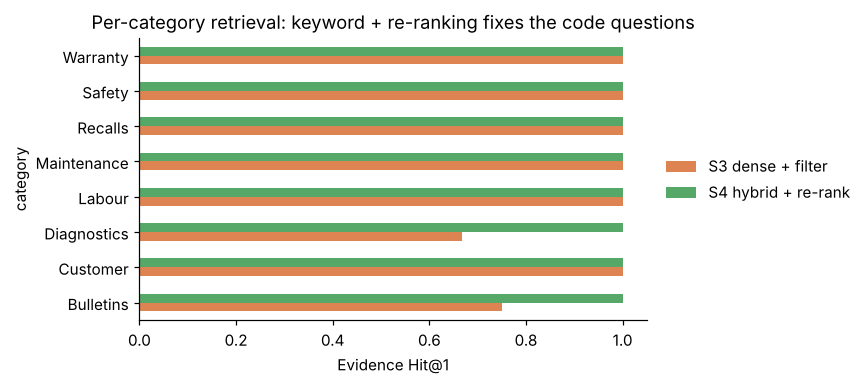

,Key-fact accuracy,Negative rejection,Safety key-facts,Evidence Hit@1,MRR,Stale-source rate,Wrongly refused,Latency p95 (ms)
S0 Chatbot (no RAG),0.00,0.0,0.0,NaN,NaN,NaN,NaN,NaN
S1 Naive RAG,0.44,0.0,0.0,0.45,0.57,0.09,0.0,19.96
S2 + recursive chunking,0.87,0.0,1.0,0.86,0.92,0.05,0.0,20.41
S3 + metadata filter,0.90,0.0,1.0,0.91,0.94,0.00,0.0,18.65
S4 + hybrid + re-rank,1.00,0.0,1.0,1.00,1.00,0.00,0.0,245.44


In [22]:
from rank_bm25 import BM25Okapi
STOP = set("a an the is are do does i my me to of for in on at and or what how when can will be it this which up should we us".split())
tokenize = lambda s: [w for w in re.findall(r"[a-z0-9]+(?:[-.][0-9a-z]+)*", s.lower()) if w not in STOP]
bm25 = BM25Okapi([tokenize(c["text"]) for c in store_rec.chunks])

def hybrid_rerank(store, q, k=10):
    d_ids, _ = store.dense(q, 20, where={"status": "current"})
    b = bm25.get_scores(tokenize(q))
    b_ids = [i for i in np.argsort(-b) if b[i] > 0 and store.chunks[i]["status"] == "current"][:20]
    fused = {}
    for lst in (d_ids, b_ids):
        for rank, i in enumerate(lst, 1): fused[i] = fused.get(i, 0) + 1 / (60 + rank)
    cands = sorted(fused, key=fused.get, reverse=True)[:10]
    scores = reranker.predict([(q, store.chunks[i]["text"]) for i in cands])
    order = np.argsort(-scores)
    return [cands[j] for j in order[:k]], [float(scores[j]) for j in order[:k]]

s4_df, s4 = evaluate(store_rec, hybrid_rerank, name="S4 + hybrid + re-rank")
HISTORY.append(s4)
cat_table["S4 hybrid + re-rank"] = per_category(s4_df)
fig, ax = plt.subplots(figsize=(8, 3.6))
cat_table.plot.barh(ax=ax, color=[ORANGE, GREEN]); ax.set_xlim(0, 1.05); ax.set_xlabel("Evidence Hit@1")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
ax.set_title("Per-category retrieval: keyword + re-ranking fixes the code questions"); plt.tight_layout(); plt.show()
pd.concat(HISTORY, axis=1).T.round(2)

---
## 🔴 Problem 5: it answers questions it should refuse
Ask about something the documents don't cover:

In [23]:
for q in OUT_OF_SCOPE[:2]:
    ids, scores = hybrid_rerank(store_rec, q)
    print("Q:", q); print("A:", store_rec.chunks[ids[0]]["text"][:110], "...\n")

Q: What is the ex-showroom price of the Nexa Max?
A: Standard labour times for the Nexa EV, in hours: front brake pads 1.0; 12 V battery replacement 0.4; wheel ali ...



Q: What is this quarter's incentive for service advisors?
A: A loaner car is offered when a warranty repair will take more than 24 hours. Pick-up and drop is free within 1 ...



Retrieval **always** returns something, so the bot answers a price question with warranty text. A confident wrong answer to a customer about price, or an advisor's incentive, is a real business risk.

### 📏 Evaluation: negative-rejection rate
Share of out-of-scope questions the bot refuses. Gate: **100%**, without refusing real questions (**wrongly refused** must stay at 0%).

Which score can tell "in scope" from "out of scope"? Compare the two candidates:

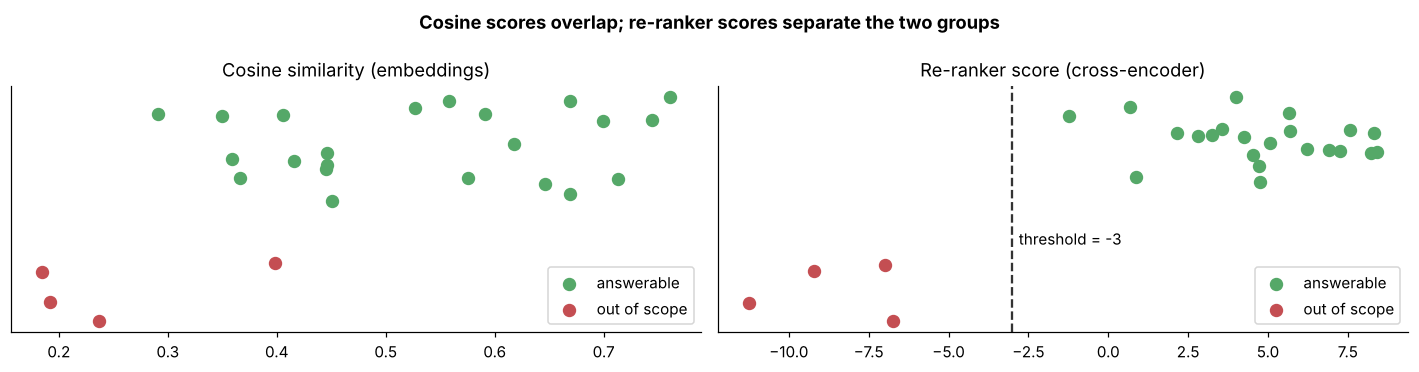

In [24]:
in_q = [g[0] for g in GOLDEN]
cos_in  = [store_rec.dense(q, 1, where={"status": "current"})[1][0] for q in in_q]
cos_out = [store_rec.dense(q, 1, where={"status": "current"})[1][0] for q in OUT_OF_SCOPE]
rr_in   = [hybrid_rerank(store_rec, q, 1)[1][0] for q in in_q]
rr_out  = [hybrid_rerank(store_rec, q, 1)[1][0] for q in OUT_OF_SCOPE]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
for ax, (a, b, title, thr) in zip(axes, [(cos_in, cos_out, "Cosine similarity (embeddings)", None),
                                         (rr_in, rr_out, "Re-ranker score (cross-encoder)", -3)]):
    ax.scatter(a, np.random.uniform(0.6, 1, len(a)), color=GREEN, s=60, label="answerable")
    ax.scatter(b, np.random.uniform(0, 0.4, len(b)), color=RED, s=60, label="out of scope")
    if thr is not None: ax.axvline(thr, ls="--", color="#333"); ax.text(thr + 0.2, 0.45, f"threshold = {thr}")
    ax.set_yticks([]); ax.set_title(title); ax.legend(loc="lower right")
fig.suptitle("Cosine scores overlap; re-ranker scores separate the two groups", fontweight="bold")
plt.tight_layout(); plt.show()

### 🛠️ Fix: a relevance threshold on the re-ranker score
If the best chunk scores below the threshold, reply *"I couldn't find this..."* instead of answering. The chart shows why we threshold the **re-ranker** score: cosine similarity of out-of-scope questions overlaps with real ones.

In [25]:
THRESHOLD = -3.0
def refuse_if_unsure(store, q, ids, scores):
    return REFUSAL if scores[0] < THRESHOLD else "ok"

s5_df, s5 = evaluate(store_rec, hybrid_rerank, answer_fn=refuse_if_unsure, name="S5 + refusal threshold")
HISTORY.append(s5)
pd.concat(HISTORY, axis=1).T.round(2)

,Key-fact accuracy,Negative rejection,Safety key-facts,Evidence Hit@1,MRR,Stale-source rate,Wrongly refused,Latency p95 (ms)
S0 Chatbot (no RAG),0.00,0.0,0.0,NaN,NaN,NaN,NaN,NaN
S1 Naive RAG,0.44,0.0,0.0,0.45,0.57,0.09,0.0,19.96
S2 + recursive chunking,0.87,0.0,1.0,0.86,0.92,0.05,0.0,20.41
S3 + metadata filter,0.90,0.0,1.0,0.91,0.94,0.00,0.0,18.65
S4 + hybrid + re-rank,1.00,0.0,1.0,1.00,1.00,0.00,0.0,245.44
S5 + refusal threshold,1.00,1.0,1.0,1.00,1.00,0.00,0.0,246.89


---
## 🔴 Problem 6: correct answers that nobody can verify
A warranty auditor rejects a claim and asks: *"Where does it say that?"* The technician has the bot's answer but **no source**. In a regulated, safety-relevant workshop, an answer without a source is not usable.

### 📏 Evaluation: citation accuracy (+ LLM judge)
- **Citation accuracy:** does the answer cite the correct document?
- **LLM-as-a-judge** (optional, needs an API key): grades correctness, faithfulness and safety with a rubric

### 🛠️ Fix: grounded answers with citations
Every answer now carries the document ID and its effective date. With an API key, an LLM writes a short answer from the top chunks with citations; without a key we return the evidence chunk with its citation.

In [26]:
DOC_META = {d["doc_id"]: d for d in DOCUMENTS}

def answer_with_citation(q, k=3):
    t0 = time.perf_counter()
    ids, scores = hybrid_rerank(store_rec, q, k)
    if scores[0] < THRESHOLD:
        return {"answer": REFUSAL, "sources": [], "latency_ms": (time.perf_counter() - t0) * 1000}
    top = [store_rec.chunks[i] for i in ids if scores[ids.index(i)] >= THRESHOLD]
    if HAS_LLM:
        ctx = "\n".join(f"[{c['doc_id']}, effective {c['effective']}] {c['text']}" for c in top)
        text = ask_llm("Answer the service-centre question using ONLY these documents. Keep it to 1-3 sentences, keep every "
                       "number and part number exact, put safety warnings first, and end with the document ID in "
                       f"square brackets. If the documents don't answer it, reply exactly: {REFUSAL}\n\n{ctx}\n\nQuestion: {q}")
    else:
        c = top[0]; text = f"{c['text']} [{c['doc_id']}, effective {c['effective']}]"
    cited = re.findall(r"\[([A-Z0-9-]+)", text)
    return {"answer": text, "sources": cited, "latency_ms": (time.perf_counter() - t0) * 1000}

cit = []
for q, ref, doc, ev, cat in GOLDEN:
    out = answer_with_citation(q)
    cit.append({"question": q, "category": cat, "answer": out["answer"], "cites_gold": float(doc in out["sources"]),
                "key_fact": key_fact_accuracy(out["answer"], ref), "latency_ms": out["latency_ms"]})
cit = pd.DataFrame(cit)
oos_ok = np.mean([is_refusal(answer_with_citation(q)["answer"]) for q in OUT_OF_SCOPE])
s6 = s5.copy(); s6.name = "S6 + citations"
s6["Key-fact accuracy"] = cit.key_fact.mean(); s6["Safety key-facts"] = cit[cit.category == "Safety"].key_fact.mean()
s6["Negative rejection"] = oos_ok; s6["Latency p95 (ms)"] = cit.latency_ms.quantile(0.95)
s6["Citation accuracy"] = cit.cites_gold.mean()
HISTORY.append(s6)
print(answer_with_citation("Car shows P0AA6. Can the customer drive it home?")["answer"])
print(f"\nCitation accuracy: {cit.cites_gold.mean():.0%}")

DTC P0AA6: high-voltage isolation fault. SAFETY CRITICAL: the car must not be driven. Only HV-certified technicians may inspect it, wearing class 0 insulated gloves. DTC U0100: lost communication with the motor control unit. Check CAN bus connector C12 for corrosion, then clean and re-seat it. [DTC-GUIDE, effective 2025-06-01]

Citation accuracy: 100%


In [27]:
JUDGE = """Grade this service-centre assistant answer. Reply with JSON only:
{{"correct": 1-5, "faithful": 1-5, "safety_ok": true/false, "reason": "..."}}
Question: {q}
Reference answer: {ref}
Assistant answer: {a}"""

if HAS_LLM:
    grades = []
    for q, ref, *_ in GOLDEN:
        raw = ask_llm(JUDGE.format(q=q, ref=ref, a=cit.set_index("question").loc[q, "answer"]), 200)
        grades.append(json.loads(raw[raw.find("{"): raw.rfind("}") + 1]))
    print(pd.DataFrame(grades)[["correct", "faithful", "safety_ok"]].mean(numeric_only=False))
else:
    print("LLM judge skipped (no API key). The rubric it would use:\n"); print(JUDGE)

LLM judge skipped (no API key). The rubric it would use:

Grade this service-centre assistant answer. Reply with JSON only:
{{"correct": 1-5, "faithful": 1-5, "safety_ok": true/false, "reason": "..."}}
Question: {q}
Reference answer: {ref}
Assistant answer: {a}


---
## 🏁 Final scorecard: is the problem solved?

In [28]:
board = pd.concat(HISTORY, axis=1).T
GATES = {"Key-fact accuracy": (">=", 0.95), "Evidence Hit@1": (">=", 0.95), "Stale-source rate": ("<=", 0.0),
         "Negative rejection": (">=", 1.0), "Safety key-facts": (">=", 1.0), "Citation accuracy": (">=", 1.0),
         "Latency p95 (ms)": ("<=", 2000)}

def gate_ok(v, op, t): return (v >= t) if op == ">=" else (v <= t)
view = board[list(GATES)].copy().astype(object)
for m, (op, t) in GATES.items():
    view[m] = [("—" if pd.isna(v) else f"{v:.2f} {'✅' if gate_ok(v, op, t) else '❌'}") for v in board[m]]
view["All gates"] = ["✅ SHIP" if all((not pd.isna(board.loc[s, m])) and gate_ok(board.loc[s, m], op, t)
                                     for m, (op, t) in GATES.items()) else "❌" for s in board.index]
view

,Key-fact accuracy,Evidence Hit@1,Stale-source rate,Negative rejection,Safety key-facts,Citation accuracy,Latency p95 (ms),All gates
S0 Chatbot (no RAG),0.00 ❌,—,—,0.00 ❌,0.00 ❌,—,—,❌
S1 Naive RAG,0.44 ❌,0.45 ❌,0.09 ❌,0.00 ❌,0.00 ❌,—,19.96 ✅,❌
S2 + recursive chunking,0.87 ❌,0.86 ❌,0.05 ❌,0.00 ❌,1.00 ✅,—,20.41 ✅,❌
S3 + metadata filter,0.90 ❌,0.91 ❌,0.00 ✅,0.00 ❌,1.00 ✅,—,18.65 ✅,❌
S4 + hybrid + re-rank,1.00 ✅,1.00 ✅,0.00 ✅,0.00 ❌,1.00 ✅,—,245.44 ✅,❌
S5 + refusal threshold,1.00 ✅,1.00 ✅,0.00 ✅,1.00 ✅,1.00 ✅,—,246.89 ✅,❌
S6 + citations,1.00 ✅,1.00 ✅,0.00 ✅,1.00 ✅,1.00 ✅,1.00 ✅,259.46 ✅,✅ SHIP


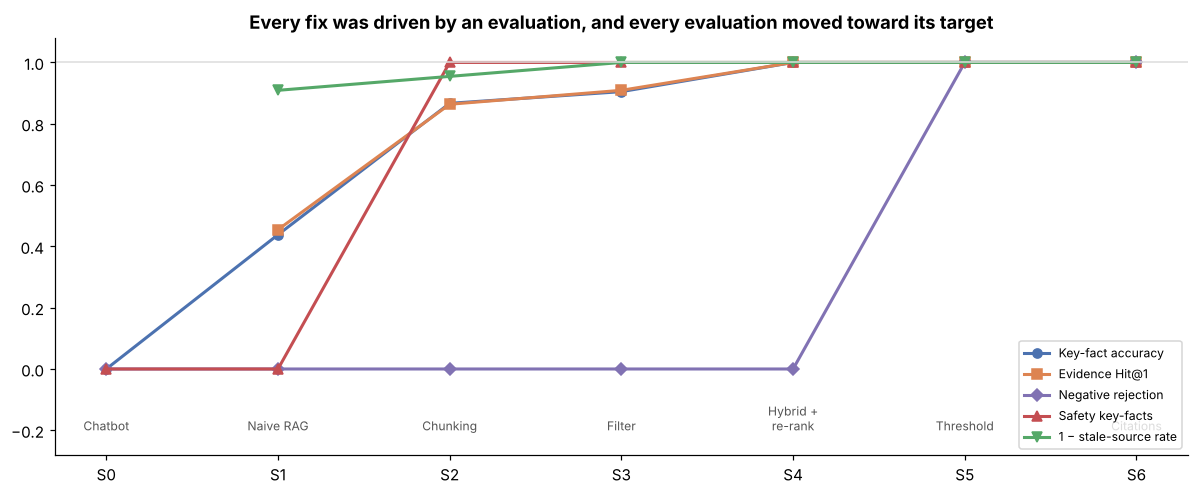

In [29]:
track = ["Key-fact accuracy", "Evidence Hit@1", "Negative rejection", "Safety key-facts"]
stages = [s.split(" ")[0] for s in board.index]
fig, ax = plt.subplots(figsize=(11, 4.6))
for m, c, mk in zip(track, [BLUE, ORANGE, PURPLE, RED], "osD^"):
    ax.plot(stages, board[m], marker=mk, color=c, lw=2, label=m)
ax.plot(stages, 1 - board["Stale-source rate"], marker="v", color=GREEN, lw=2, label="1 − stale-source rate")
labels = ["Chatbot", "Naive RAG", "Chunking", "Filter", "Hybrid +\nre-rank", "Threshold", "Citations"]
for x, l in enumerate(labels): ax.text(x, -0.2, l, ha="center", fontsize=8, color="#555")
ax.set_ylim(-0.28, 1.08); ax.axhline(1, color="#ddd", lw=1); ax.legend(loc="lower right", fontsize=8)
ax.set_title("Every fix was driven by an evaluation, and every evaluation moved toward its target", fontweight="bold")
plt.tight_layout(); plt.show()

### 💼 Business impact (scenario estimate)
Evaluation numbers become a business case when combined with simple, clearly stated assumptions:

In [30]:
QUERIES_PER_DAY = 40 * 15          # 40 service centres x 15 questions a day (assumption)
MIN_MANUAL, MIN_WITH_BOT = 10, 1   # minutes to find an answer manually vs read + verify the bot's answer (assumption)
WORK_DAYS = 26

def wrong_per_1000(stage):
    """Answerable questions answered with a wrong fact, per 1,000 questions."""
    return round((1 - board.loc[stage, "Key-fact accuracy"]) * 1000)

hours_saved = QUERIES_PER_DAY * (MIN_MANUAL - MIN_WITH_BOT) * WORK_DAYS / 60
print(f"Advisor hours saved per month: ~{hours_saved:,.0f}")
for s in [board.index[0], board.index[1], board.index[-1]]:
    print(f"Wrong facts per 1,000 questions, {s:24s}: {wrong_per_1000(s)}")

Advisor hours saved per month: ~2,340
Wrong facts per 1,000 questions, S0 Chatbot (no RAG)     : 1000
Wrong facts per 1,000 questions, S1 Naive RAG            : 562
Wrong facts per 1,000 questions, S6 + citations          : 0


## 🧾 Summary: which evaluation solves which problem

| Problem we saw | Real example | Evaluation that detected it | Fix |
|---|---|---|---|
| Hallucination | "P0AA6: car can be driven carefully" | Key-fact accuracy, faithfulness (NLI) | RAG over Volta documents |
| Broken context | Chunk starting mid-sentence, mixing two codes | Evidence Hit@1 / context recall | Recursive chunking with overlap |
| Outdated source | TSB Revision 1 (65 Nm) instead of Revision 2 | Stale-source rate | Metadata filter on `status` |
| Similar codes | P0A80 answered with P0AA6 | Per-category Hit@1, MRR | BM25 hybrid + cross-encoder re-ranking |
| Answers everything | Price question answered with warranty text | Negative-rejection rate | Threshold on re-ranker score |
| Unverifiable | "Where does it say that?" | Citation accuracy, LLM judge | Answers cite document ID and date |

**The lesson:** you can't fix what you don't measure. Each metric is a **detector** for one kind of failure, and a RAG system is ready when every detector is quiet.

## 🎯 Try it: the finished assistant

In [31]:
def ask(question):
    out = answer_with_citation(question)
    print(f"Q: {question}\nA: {out['answer']}\n   ({out['latency_ms']:.0f} ms)\n")

ask("Customer reports front suspension rattle over speed bumps. What is the fix?")
ask("Scan tool shows P0A7F. What next?")
ask("What is the ex-showroom price of the Nexa Max?")

Q: Customer reports front suspension rattle over speed bumps. What is the fix?
A: TSB-24-017 Revision 2 (supersedes Revision 1). Concern: rattling noise from the front suspension when driving over speed bumps on the Nexa EV. Repair: replace both front stabiliser links with part VL-31400-B and torque the nuts to 80 Nm. Labour time 1.2 hours. [TSB-24-017-R2, effective 2026-02-01]
   (257 ms)



Q: Scan tool shows P0A7F. What next?
A: DTC P0A80: one or more battery cells below voltage. Run the cell balance test with VDS. If any cell reads below 3.0 V, replace that battery module. Covered by battery warranty. DTC P0A7F: battery pack deterioration, capacity below 70%. Run the capacity test and claim under the battery warranty if the car is within 8 years or 160,000 km. [DTC-GUIDE, effective 2025-06-01]
   (238 ms)



Q: What is the ex-showroom price of the Nexa Max?
A: I couldn't find this in the Volta service documents. Please check with the service manager.
   (227 ms)



## 📝 Exercises
1. **New failure, new metric.** Add a 2025 version of the customer policy that says "update every 8 hours" but forget to mark it `superseded`. Which metric catches it? What process fix prevents it?
2. **Chunk size.** Re-run Problem 2 with recursive chunks of 150 and 1,000 characters. Plot Evidence Hit@1 and key-fact accuracy for each size.
3. **Threshold tuning.** Try thresholds −6, −3, 0 and 2. For each, report negative rejection *and* wrongly refused. Which would you ship, and why?
4. **Harder test set.** Write 5 questions in Hinglish or with typos ("p0aa6 aaya hai, gaadi chala sakte?"). Which stage's metrics drop?
5. **With an API key:** switch on the LLM generator and the LLM judge. Does an LLM-written answer keep every number exact? Which metric would catch it if it didn't?